In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/organizations/uciml/pima-indians-diabetes-database/diabetes.csv


In [6]:
data = pd.read_csv('/kaggle/input/datasets/organizations/uciml/pima-indians-diabetes-database/diabetes.csv')

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
X = data.drop('Outcome', axis=1)
y = data['Outcome']

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [10]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [18]:
y_scores = model.predict_proba(X_test)[:,1] 

In [19]:
y_scores

array([0.04953614, 0.17457598, 0.09361881, 0.25506885, 0.63547544,
       0.11671368, 0.06567023, 0.42188399, 0.04866172, 0.57563331,
       0.33875755, 0.41304766, 0.69854116, 0.19964149, 0.02001751,
       0.82471066, 0.86656925, 0.03101004, 0.25510704, 0.89492503,
       0.95246417, 0.83478816, 0.11740638, 0.44669903, 0.08923277,
       0.0688273 , 0.65117568, 0.41197875, 0.17860377, 0.28690155,
       0.24546297, 0.43904474, 0.00942529, 0.24260485, 0.35171265,
       0.96164606, 0.34360459, 0.80926014, 0.29380482, 0.0508316 ,
       0.18185164, 0.08671687, 0.42233336, 0.18738035, 0.03011578,
       0.03949078, 0.24740821, 0.42784702, 0.10529277, 0.37970704,
       0.99355928, 0.10665836, 0.39100545, 0.76883113, 0.36866729,
       0.45776991, 0.95035238, 0.41990462, 0.39153693, 0.04376   ,
       0.37295079, 0.90128751, 0.88176468, 0.88842753, 0.33083729,
       0.06930532, 0.9526512 , 0.20057864, 0.260557  , 0.35464146,
       0.10359002, 0.08168553, 0.45043617, 0.09221098, 0.08648

In [12]:
y_pred = model.predict(X_test)

In [32]:
from sklearn.metrics import roc_curve,auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_scores)

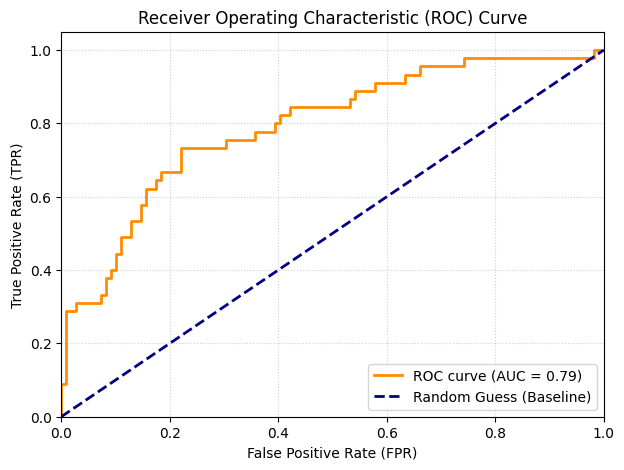

In [33]:
roc_auc = auc(fpr, tpr)

# 4. Plot using Matplotlib
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Guess (Baseline)")

# Graph labels and bounds
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [21]:
fpr

array([0.        , 0.        , 0.        , 0.00917431, 0.00917431,
       0.02752294, 0.02752294, 0.0733945 , 0.0733945 , 0.08256881,
       0.08256881, 0.09174312, 0.09174312, 0.10091743, 0.10091743,
       0.11009174, 0.11009174, 0.12844037, 0.12844037, 0.14678899,
       0.14678899, 0.1559633 , 0.1559633 , 0.17431193, 0.17431193,
       0.18348624, 0.18348624, 0.22018349, 0.22018349, 0.30275229,
       0.30275229, 0.35779817, 0.35779817, 0.39449541, 0.39449541,
       0.40366972, 0.40366972, 0.42201835, 0.42201835, 0.53211009,
       0.53211009, 0.5412844 , 0.5412844 , 0.57798165, 0.57798165,
       0.63302752, 0.63302752, 0.66055046, 0.66055046, 0.74311927,
       0.74311927, 0.98165138, 0.98165138, 1.        ])

In [22]:
tpr

array([0.        , 0.02222222, 0.08888889, 0.08888889, 0.28888889,
       0.28888889, 0.31111111, 0.31111111, 0.33333333, 0.33333333,
       0.37777778, 0.37777778, 0.4       , 0.4       , 0.44444444,
       0.44444444, 0.48888889, 0.48888889, 0.53333333, 0.53333333,
       0.57777778, 0.57777778, 0.62222222, 0.62222222, 0.64444444,
       0.64444444, 0.66666667, 0.66666667, 0.73333333, 0.73333333,
       0.75555556, 0.75555556, 0.77777778, 0.77777778, 0.8       ,
       0.8       , 0.82222222, 0.82222222, 0.84444444, 0.84444444,
       0.86666667, 0.86666667, 0.88888889, 0.88888889, 0.91111111,
       0.91111111, 0.93333333, 0.93333333, 0.95555556, 0.95555556,
       0.97777778, 0.97777778, 1.        , 1.        ])

In [25]:
thresholds

array([       inf, 0.99355928, 0.9526512 , 0.95246417, 0.82471066,
       0.76883113, 0.76198112, 0.68385812, 0.67529148, 0.67422748,
       0.65117568, 0.65085312, 0.63547544, 0.58630057, 0.57563331,
       0.56974552, 0.52514581, 0.47017119, 0.46131937, 0.45043617,
       0.43904474, 0.43865745, 0.42233336, 0.41990462, 0.41304766,
       0.41197875, 0.40477801, 0.37970704, 0.36866729, 0.31020305,
       0.30880354, 0.27772349, 0.27205111, 0.25510704, 0.25506885,
       0.24740821, 0.24546297, 0.23665336, 0.22887288, 0.18185164,
       0.17860377, 0.17457598, 0.1732547 , 0.14638332, 0.14074927,
       0.11671368, 0.11494479, 0.11000892, 0.10665836, 0.08923277,
       0.08671687, 0.02001751, 0.01931547, 0.00160784])

In [26]:
from sklearn.metrics import RocCurveDisplay

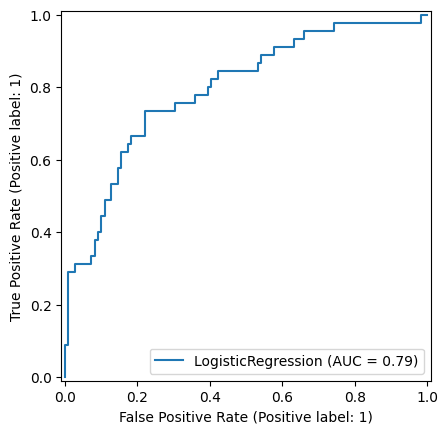

In [28]:
RocCurveDisplay.from_estimator(model, X_test, y_test)

In [36]:
import numpy as np
from sklearn.metrics import roc_curve

# 1. Get the rates and corresponding thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# 2. Calculate Youden's J statistic for every point
j_scores = tpr - fpr

# 3. Find the index of the highest J score
best_index = np.argmax(j_scores)
optimal_threshold = thresholds[best_index]

print(f"The optimal threshold is: {optimal_threshold:.4f}")
print(f"At this threshold, TPR={tpr[best_index]:.2f} and FPR={fpr[best_index]:.2f}")
Use code with caution.Would you like to know how to adjust this threshold based on whether minimizing false alarms or catching every positive case is more important for your project?

The optimal threshold is: 0.3687
At this threshold, TPR=0.73 and FPR=0.22
Object `project` not found.


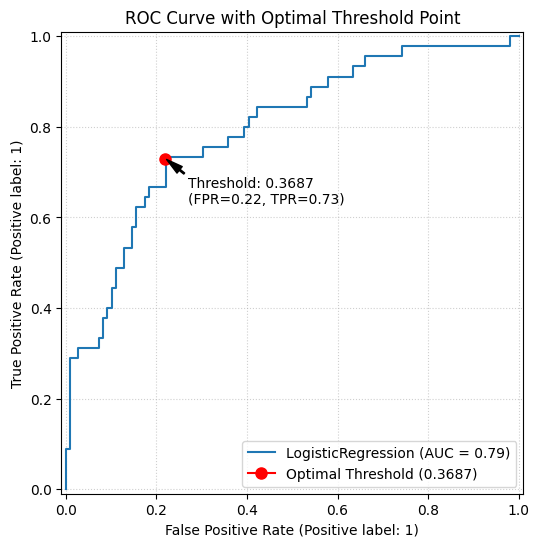

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# 1. Plot the standard ROC curve using your model
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax)

# 2. Define your calculated optimal points
optimal_fpr = 0.22
optimal_tpr = 0.73
optimal_threshold = 0.3687

# 3. Plot the red dot at the exact (FPR, TPR) coordinate
ax.plot(optimal_fpr, optimal_tpr, marker='o', color='red', markersize=8, label=f'Optimal Threshold ({optimal_threshold:.4f})')

# 4. Add a dashed line or annotation text next to the dot
ax.annotate(f'Threshold: {optimal_threshold:.4f}\n(FPR={optimal_fpr}, TPR={optimal_tpr})',
            xy=(optimal_fpr, optimal_tpr),
            xytext=(optimal_fpr + 0.05, optimal_tpr - 0.1), # Offset the text slightly
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# 5. Refresh the legend and display
plt.legend(loc="lower right")
plt.title("ROC Curve with Optimal Threshold Point")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [38]:
import numpy as np
import plotly.graph_objects as go
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler

# Assuming that X_train, X_test, y_train, y_test are already defined

# SVM requires feature scaling for better performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_scores = lr_model.predict_proba(X_test)[:,1]

# SVM model
svm_model = SVC(probability=True)
svm_model.fit(X_train_scaled, y_train)
svm_scores = svm_model.predict_proba(X_test_scaled)[:,1]

# Generate ROC curve data for logistic regression model
lr_fpr, lr_tpr, lr_thresholds = roc_curve(y_test, lr_scores)
lr_auc = roc_auc_score(y_test, lr_scores)

# Generate ROC curve data for SVM model
svm_fpr, svm_tpr, svm_thresholds = roc_curve(y_test, svm_scores)
svm_auc = roc_auc_score(y_test, svm_scores)

# Generate a trace for the Logistic Regression ROC curve
trace0 = go.Scatter(
    x=lr_fpr,
    y=lr_tpr,
    mode='lines',
    name=f'Logistic Regression (Area = {lr_auc:.2f})'
)

# Generate a trace for the SVM ROC curve
trace1 = go.Scatter(
    x=svm_fpr,
    y=svm_tpr,
    mode='lines',
    name=f'SVM (Area = {svm_auc:.2f})'
)

# Diagonal line
trace2 = go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode='lines',
    name='Random (Area = 0.5)',
    line=dict(dash='dash')
)

data = [trace0, trace1, trace2]

# Define layout with square aspect ratio
layout = go.Layout(
    title='Receiver Operating Characteristic',
    xaxis=dict(title='False Positive Rate'),
    yaxis=dict(title='True Positive Rate'),
    autosize=False,
    width=800,
    height=800,
    showlegend=True
)

# Define figure and add data
fig = go.Figure(data=data, layout=layout)

# Show figure
fig.show()

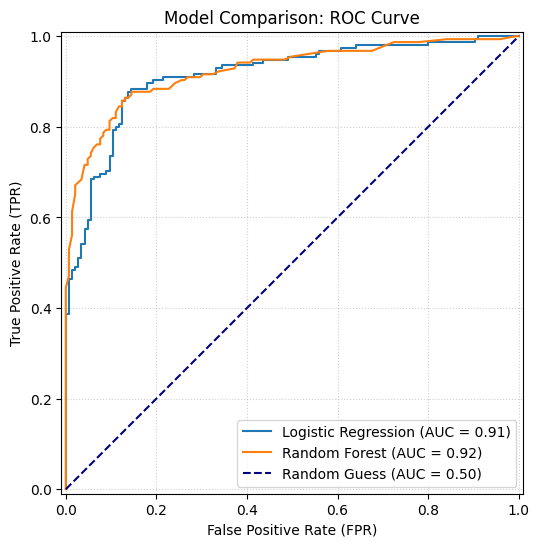

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

# 1. Setup the exact same data split
X, y = make_classification(n_samples=1000, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. Define and train both models
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train, y_train)

# This is your new second model
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)

# 3. Create a unified plot axis
fig, ax = plt.subplots(figsize=(7, 6))

# 4. Draw both curves onto the exact same plot
RocCurveDisplay.from_estimator(model_lr, X_test, y_test, ax=ax, name="Logistic Regression")
RocCurveDisplay.from_estimator(model_rf, X_test, y_test, ax=ax, name="Random Forest")

# 5. Add a diagonal reference baseline (random guessing = 0.50)
ax.plot([0, 1], [0, 1], color="navy", linestyle="--", label="Random Guess (AUC = 0.50)")

# 6. Customize chart decorations
plt.title("Model Comparison: ROC Curve")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()
